# Task 1 — Preattentive attributes and visual search

**Status:** all supplied-data analysis is executed. Human observations are deliberately unfilled. Run the interactive collection cell, use a real reader, then rerun the analysis cells below it. Blank responses are not evidence. No simulated results are used.

Charts use the object-oriented Matplotlib API. Experimental stimuli intentionally retain the supplied colours and omit titles where the brief requires this; they are displays for testing perception, not final explanatory charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Wedge
from IPython.display import display
DATA = Path('data'); RESULTS = Path('results'); FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 42
GREY = '#b9bdc3'; ACCENT = '#bd3f58'
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
def clean(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
def save(fig, name):
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight')


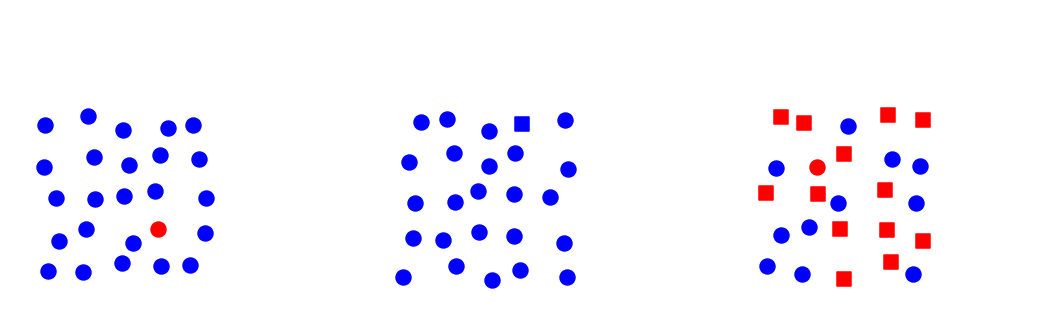

In [2]:
stimuli = pd.read_csv(DATA/'stimuli_search.csv')
def draw_trial(trial, ax):
    frame = stimuli.loc[stimuli.trial.eq(trial)]
    for (colour, shape), items in frame.groupby(['colour','shape']):
        ax.scatter(items.x, items.y, c=colour, marker={'circle':'o','square':'s'}[shape], s=95)
    ax.set_xlim(-.6,7.6); ax.set_ylim(-.6,7.6); ax.set_aspect('equal'); ax.set_axis_off()
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax, condition in zip(axes, ['colour','shape','conjunction']):
    trial = stimuli.query('condition == @condition and set_size == 25 and target_present == "yes"').trial.iloc[0]
    draw_trial(trial, ax)
save(fig,'task1_stimuli.png'); plt.show()


**What the eye does:** panels are colour, shape and conjunction, left to right. Hue and shape encode nominal features; position is a controlled layout, not a quantitative variable. Similarity groups distractors. A red circle has a unique hue in the first display, and a square a unique shape in the second; in the third each feature is shared with distractors, so feature binding requires attention. The stimuli are exceptions to the one-colour final-chart rule. No rows were excluded from each displayed trial.

## Real-reader protocol
The brief requests 18 trials but also two trials in all 15 condition × size cells (30 trials). This implementation selects 9, 25 and 49: 3 conditions × 3 sizes × 2 presence states = 18. Record this limitation. Tell the target **before** each block, let the reader practise verbally, and click the show button only after they are ready. The reader clicks Yes or No. `perf_counter()` measures kernel dispatch to response; browser/render/communication delay is included, so this is approximate manual timing, not laboratory response timing. Keep screen and device unchanged. Avoid showing answer keys. One reader, only three present trials per condition.

In [3]:
import time
import ipywidgets as widgets
meta = stimuli.drop_duplicates('trial')
selected = (meta[meta.set_size.isin([9,25,49])].sort_values('trial')
            .groupby(['condition','set_size','target_present'],sort=False).head(1))
# Blocks remain separate so the reader can learn the target before each block.
blocks = [selected[selected.condition.eq(c)].sample(frac=1,random_state=SEED) for c in ['colour','shape','conjunction']]
schedule = pd.concat(blocks).reset_index(drop=True)
path = RESULTS/'search_results.csv'
if not path.exists():
    schedule[['trial','condition','set_size','target_present']].assign(participant='',response='',response_time_ms=np.nan,correct=pd.NA).to_csv(path,index=False)
participant = widgets.Text(description='Reader:')
start = widgets.Button(description='Show next trial')
yes = widgets.Button(description='Yes'); no = widgets.Button(description='No')
out = widgets.Output(); status = widgets.HTML(); state={'i':0,'start':None,'row':None}
def next_search(_):
    if not participant.value.strip(): status.value='Enter the real reader’s first name or description.'; return
    if state['start'] is not None: return
    if state['i'] >= len(schedule): status.value='Finished. Rerun the analysis cell.'; return
    row=schedule.iloc[state['i']]; state['row']=row
    status.value='Is the target there, yes or no?'
    with out:
        out.clear_output(wait=True)
        fig,ax=plt.subplots(figsize=(5,5));draw_trial(row.trial,ax);display(fig);plt.close(fig)
    state['start']=time.perf_counter()
def answer_search(response):
    if state['start'] is None: return
    elapsed=(time.perf_counter()-state['start'])*1000
    row=state['row']; frame=pd.read_csv(path)
    idx=frame.index[frame.trial.eq(row.trial)][0]
    frame.loc[idx,['participant','response','response_time_ms','correct']]=[participant.value.strip(),response,elapsed,response==row.target_present]
    frame.to_csv(path,index=False);state['i']+=1;state['start']=None
    brief_search()
def brief_search():
    if state['i'] >= len(schedule): status.value='Finished. Rerun the analysis cell.'; return
    condition=schedule.iloc[state['i']].condition
    target={'colour':'red circle','shape':'blue square','conjunction':'red circle'}[condition]
    status.value=f'Before the trial: {condition} block; find a {target}. Tell the reader, then show next when ready.'
brief_search()
start.on_click(next_search);yes.on_click(lambda _:answer_search('yes'));no.on_click(lambda _:answer_search('no'))
display(widgets.VBox([participant,status,start,out,widgets.HBox([yes,no])]))


In [4]:
results=pd.read_csv(path)
display(results)
observed=results.dropna(subset=['response_time_ms','response'])
present=observed[observed.target_present.eq('yes') & observed.response.eq('yes')]
if present.empty:
    print('PENDING: no real-reader target-present measurements; slopes and response-time chart cannot be reported.')
else:
    fig,ax=plt.subplots(figsize=(8,5)); slopes=[]
    for condition, d in present.groupby('condition'):
        d=d.groupby('set_size',as_index=False).response_time_ms.mean().sort_values('set_size')
        ax.plot(d.set_size,d.response_time_ms,marker={'colour':'o','shape':'s','conjunction':'^'}[condition],
                color=ACCENT if condition=='conjunction' else GREY, linestyle='-' if condition=='conjunction' else '--',label=condition)
        if d.set_size.nunique()>=2:
            slope,intercept=np.polyfit(d.set_size,d.response_time_ms,1);slopes.append({'condition':condition,'slope_ms_per_item':slope})
    ax.set(title='Does conjunction search slow as displays grow?',xlabel='Items in display',ylabel='Mean response time (ms)')
    ax.legend();clean(ax);save(fig,'task1_response_times.png');plt.show();display(pd.DataFrame(slopes))
    print('Accuracy:', (observed.response == observed.target_present).mean())
    print('Report signs and magnitudes honestly; do not force a positive conjunction slope. Incorrect trials are excluded from RT fitting.')


PENDING: no real-reader target-present measurements; slopes and response-time chart cannot be reported.


,trial,condition,set_size,target_present,participant,response,response_time_ms,correct
0,1,colour,9,yes,NaN,NaN,NaN,NaN
1,4,colour,9,no,NaN,NaN,NaN,NaN
2,28,colour,49,no,NaN,NaN,NaN,NaN
3,13,colour,25,yes,NaN,NaN,NaN,NaN
4,25,colour,49,yes,NaN,NaN,NaN,NaN
5,16,colour,25,no,NaN,NaN,NaN,NaN
6,31,shape,9,yes,NaN,NaN,NaN,NaN
7,34,shape,9,no,NaN,NaN,NaN,NaN
8,58,shape,49,no,NaN,NaN,NaN,NaN
9,43,shape,25,yes,NaN,NaN,NaN,NaN


**Reading the analysis chart:** position on a common scale carries set size and time; connection groups each condition’s measurements. Only conjunction uses the accent; marker and line differences preserve identity without colour. Present and absent results stay separate; incorrect responses are retained in the CSV but excluded from correct-trial slopes. A near-zero slope is consistent with parallel search, a positive slope with serial search; there is no universal cutoff for “flat” here. Negative or unexpected slopes can reflect sampling noise, layout learning and timing delay. This sample cannot establish a general law.

**Conjunction explanation:** the eye can register red and circles separately, but must bind the two features at a location to know whether the same item is both. Example of a design trap: a scatterplot asking for red circular points among red triangles and grey circles. This is a hypothetical example, not a claim about the student’s previous work. **Personal reflection to finish:** name one chart you actually made and identify its conjunction request.

**Human results status:** pending until collection. After collecting, describe each measured slope, including any disagreement with the expected pattern.